# Myocardial infarction

Paper figures 10. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS or REGENERATE_FIGURES:
    import os
    for key in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
        os.environ[key] = '1'
    os.environ.setdefault('MPLCONFIGDIR', '/tmp/myocardial_redone_mpl')
    from pathlib import Path
    import hashlib, importlib, json, pickle, sys, types
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy.linalg import eigh
    from scipy.special import logsumexp
    from joblib import Parallel, delayed, parallel_config
    from IPython.display import display, Image
    ROOT = Path.cwd()
    OUT = ROOT / 'results/myocardial_redone'
    OUT.mkdir(parents=True, exist_ok=True)
    np.set_printoptions(precision=18)

    def numerical_modules():
        name = '_myocardial_redone_numerics'
        if name not in sys.modules:
            package = types.ModuleType(name)
            package.__path__ = [str(ROOT / 'WERM')]
            sys.modules[name] = package
        ss = importlib.import_module(name + '.signal_strength')
        state = importlib.import_module(name + '.myocardial_approximate')
        state.logistic_prox = importlib.import_module(name + '.myocardial_numerics').logistic_prox_fast
        proximal = importlib.import_module(name + '.proximal')
        return (ss, state, proximal)
    (ss, state_solver, proximal) = numerical_modules()


## Prepare data

In [3]:
if RUN_EXPERIMENTS:
    raw = pd.read_csv(ROOT / 'results/myocardial_raw_uci579.csv')
    frame = raw.loc[raw.AGE.notna()].sort_values('AGE', kind='stable')
    ages = frame.AGE.to_numpy(float)
    y = (frame.ZSN.to_numpy() > 0).astype(int)
    X = frame[list(raw.columns[2:112])].to_numpy(float)
    X = np.where(np.isnan(X), np.nanmean(X, axis=0), X)
    X -= X.mean(axis=0)
    (n, p) = X.shape
    (values, vectors) = eigh(X.T @ X / n + 1e-06 * np.eye(p))
    X = X @ (vectors / np.sqrt(values) @ vectors.T) / np.sqrt(n)
    (_, locations) = np.unique(ages, return_index=True)
    locations = locations[locations > 0]
    (eta, prior, phi) = ss.configuration_prior(n, locations[(locations >= 2) & (locations <= n - 2)])


## Estimate the Gram initialization

In [4]:
if RUN_EXPERIMENTS:
    (_, _, gram_weights) = ss.configuration_prior(n, locations[(locations >= 5) & (locations <= n - 5)])
    design = np.column_stack([X, np.ones(n)])
    coefficients = []
    for weights in gram_weights:
        sqrt_w = np.sqrt(weights)
        beta = np.linalg.lstsq(design * sqrt_w[:, None], y * sqrt_w, rcond=None)[0]
        coefficients.append(beta[:-1])
    B_gram = np.column_stack(coefficients)
    G = B_gram.T @ B_gram / p
    rho0 = np.diag(np.diag(G))
    display(pd.DataFrame(G).style.format('{:.16g}'))
    display(pd.DataFrame(rho0).style.format('{:.16g}'))


## Estimate $\hat\rho$

In [5]:
if RUN_EXPERIMENTS:
    B_aux = np.column_stack([np.linalg.lstsq(X * np.sqrt(w[:, None]), y * np.sqrt(w), rcond=None)[0] for w in phi])
    theta_aux = X @ B_aux
    (V_aux, _) = ss.empirical_adjustment(theta_aux, y, phi, n / p, loss='squared')
    S = V_aux.T @ V_aux / n
    errors = (theta_aux - y[:, None]) ** 2
    scores = [errors[:, 0].sum() if e < 0 else errors[:e, 0].sum() + errors[e:, 1].sum() for e in eta]
    pilot = int(eta[np.argmin(scores)])
    psi = np.zeros(n, int) if pilot < 0 else (np.arange(n) >= pilot).astype(int)

    def project_covariance(matrix):
        (eigenvalues, eigenvectors) = np.linalg.eigh((matrix + matrix.T) / 2)
        return eigenvectors * np.clip(eigenvalues, 0.0001, 100.0) @ eigenvectors.T
    rho_hat = rho0.copy()
    for _ in range(16):
        state = ss.squared_logistic_state(rho_hat, phi, psi, n / p)
        inverse = np.linalg.pinv(state['lambda'], rcond=1e-06)
        target = project_covariance(inverse.T @ (S - state['kappa']) @ inverse)
        rho_hat = project_covariance(0.75 * rho_hat + 0.25 * target)
    state = ss.squared_logistic_state(rho_hat, phi, psi, n / p)
    moment_residual = float(np.linalg.norm(state['moment'] - S, 'fro'))
    display(pd.DataFrame(rho_hat).style.format('{:.18g}'))
    original_residual = 0.07085701296666086
    reduction_percent = 100 * (1 - moment_residual / original_residual)
    display(pd.DataFrame({'Quantity': ['Original reported Frobenius residual', 'New Frobenius moment residual', 'Reduction in reported residual (%)'], 'Value': [original_residual, moment_residual, reduction_percent]}).style.hide(axis='index').format({'Value': '{:.12g}'}))


## Probability of a change point

In [6]:
if RUN_EXPERIMENTS:
    B_post = []
    for w in phi:
        curvature_bound = np.linalg.eigvalsh(X.T @ ((w / w.sum())[:, None] * X))[-1] / 4
        fitted = proximal.fit_weighted(X, y, loss='logistic', sample_weight=w, penalty='none', penalty_strength=0.0, initial=np.zeros(p), initial_step=1 / curvature_bound, max_iter=16, tol=1e-14)
        B_post.append(fitted.coef)
    (V_post, _) = ss.empirical_adjustment(X @ np.column_stack(B_post), y, phi, n / p, loss='logistic')
    digest = hashlib.sha256()
    for array in (X, y, phi, eta, prior, V_post):
        digest.update(np.ascontiguousarray(array).tobytes())
    for filename in ('signal_strength.py', 'myocardial_approximate.py', 'myocardial_numerics.py'):
        digest.update((ROOT / 'WERM' / filename).read_bytes())
    CACHE = OUT / digest.hexdigest()[:16]
    CACHE.mkdir(exist_ok=True)

    def location_likelihood(rho, index):
        key = hashlib.sha256(np.asarray(rho, float).tobytes()).hexdigest()[:16]
        path = CACHE / f'{key}_location{index:02d}.pkl'
        if path.exists():
            with path.open('rb') as file:
                return pickle.load(file)
        (equations, solver, _) = numerical_modules()
        e = eta[index]
        labels = np.zeros(n, int) if e < 0 else (np.arange(n) >= e).astype(int)
        state = solver.logistic_state(rho, phi, labels, n / p, sample_power=10, seed=123, max_nfev=100)
        ll = equations.gaussian_logistic_loglikelihood(V_post, y, rho, state['lambda'], state['kappa'], labels, quadrature_order=160)
        result = dict(log_likelihood=float(ll), state_residual=state['training_residual'])
        assert np.isfinite(ll) and result['state_residual'] < 1e-06
        with path.open('wb') as file:
            pickle.dump(result, file)
        return result

    def posterior_at(rho):
        with parallel_config(backend='loky', inner_max_num_threads=1):
            records = Parallel(n_jobs=6)((delayed(location_likelihood)(rho, i) for i in range(len(eta))))
        joint = np.array([r['log_likelihood'] for r in records]) + np.log(prior)
        probabilities = np.exp(joint - logsumexp(joint))
        conditional = np.exp(joint[1:] - logsumexp(joint[1:]))
        assert abs(probabilities.sum() - 1) < 1e-10 and abs(conditional.sum() - 1) < 1e-10
        return dict(presence=float(probabilities[1:].sum()), conditional=conditional, ages=ages[eta[1:]])
    posterior = posterior_at(rho_hat)


## Posterior location conditional on one change point

In [7]:
if REGENERATE_FIGURES:
    if not RUN_EXPERIMENTS:
        saved = np.load('results/myocardial_redone/estimates.npz')
        posterior = {'ages': saved['ages'], 'conditional': saved['conditional']}
    PAPER_WIDTH = 427.64493 / 72.27
    PANEL_WIDTH = 0.49 * PAPER_WIDTH
    SCALE = 10.5 / 18
    PAPER_STYLE = {'text.usetex': True, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman'], 'font.size': 8.5, 'axes.labelsize': 10.5, 'axes.titlesize': 10.5, 'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8, 'axes.linewidth': 0.85, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'xtick.major.width': 0.85, 'ytick.major.width': 0.85, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5, 'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180, 'figure.autolayout': False, 'figure.constrained_layout.use': False, 'legend.frameon': False, 'axes.formatter.useoffset': False, 'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white'}
    with plt.rc_context(PAPER_STYLE):
        prob = posterior['conditional']
        plot_ages = posterior['ages']
        finite = np.isfinite(plot_ages) & np.isfinite(prob)
        (fig, ax) = plt.subplots(figsize=(PAPER_WIDTH, 1.18))
        fig.subplots_adjust(left=0.11, right=0.985, bottom=0.39, top=0.96)
        (markers, stems, _) = ax.stem(plot_ages[finite], prob[finite], linefmt='k-', markerfmt='ko', basefmt=' ')
        plt.setp(stems, lw=1.05, alpha=0.8)
        plt.setp(markers, markersize=2.3, markeredgewidth=0)
        ax.set(xlim=(26, 95.1), xlabel='Age (years)')
        ax.set_xticks([26, 40, 50, 60, 75, 81, 92])
        ax.set_yticks([0, max(prob[finite])], ['0', f'{max(prob[finite]):.2f}'])
        ax.grid(axis='y', ls=':', color='gray', alpha=0.4)
        fig.canvas.draw()
        bounds = fig.bbox_inches
        for axis in fig.axes:
            box = axis.get_tightbbox(fig.canvas.get_renderer())
            assert box.x0 >= -2 and box.y0 >= -2
            assert box.x1 <= fig.bbox.width + 2 and box.y1 <= fig.bbox.height + 2
        fig.savefig(OUT / 'conditional_posterior.pdf', bbox_inches=bounds)
        fig.savefig(OUT / 'conditional_posterior.png', bbox_inches=bounds)
        plt.close(fig)
        display(Image(filename=str(OUT / 'conditional_posterior.png')))
    plt.close("all")


## Scalar sensitivity: $(1+t)\hat\rho$

In [8]:
if RUN_EXPERIMENTS:
    rows = []
    for t in [-0.2, -0.1, 0.0, 0.1, 0.2]:
        result = posterior if t == 0 else posterior_at((1 + t) * rho_hat)
        rows.append({'t': t, 'P(change point)': result['presence']})
    sensitivity = pd.DataFrame(rows)
    display(sensitivity.style.hide(axis='index').format({'t': '{:+.1f}', 'P(change point)': '{:.9f}'}))
    sensitivity.to_csv(OUT / 'scalar_sensitivity.csv', index=False)
    np.savez(OUT / 'estimates.npz', gram=G, rho0=rho0, rho_hat=rho_hat, moment_residual=moment_residual, original_residual=original_residual, reduction_percent=reduction_percent, ages=posterior['ages'], conditional=posterior['conditional'], P_change=posterior['presence'])


In [9]:
import numpy as np
import pandas as pd
summary = np.load('results/myocardial_redone/estimates.npz')
print('P(one change point) =', float(summary['P_change']))
display(pd.read_csv('results/myocardial_redone/scalar_sensitivity.csv').round(3))


P(one change point) = 0.6067804201254354


,t,P(change point)
0,-0.2,0.497
1,-0.1,0.552
2,0.0,0.607
3,0.1,0.661
4,0.2,0.713


## Figure 10

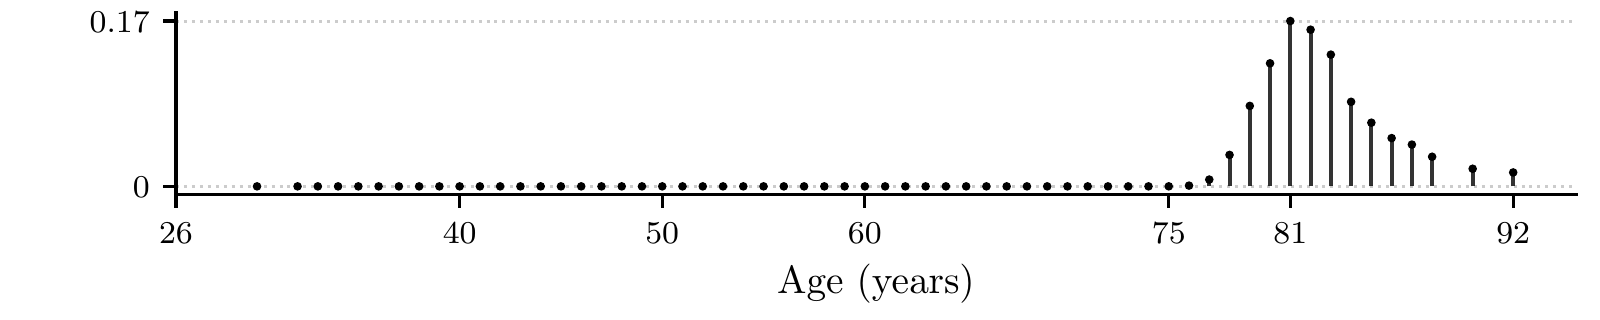

In [10]:
panels = ['results/myocardial_redone/conditional_posterior.pdf'] if REGENERATE_FIGURES else ['figures/figure_10/panel_01.pdf']
show_panels(panels)
